# 02 Estimate: baselines and SARIMA models in the backtest

**Purpose:** Produce forecasts for 1, 2 and 3 months ahead for every month of the backtest, with an expanding training window, for five candidate models (two simple baselines and three (S)ARIMA models), and for a third simple rule, the random walk, which we added after the test (section 3).
**Input:** `../data/processed/asylum_clean.csv` (from `01_preprocess.ipynb`).
**Output:** `../data/processed/backtest_forecasts.csv` (one row per model, forecast month and horizon) and one figure in `../output/figures/`.

The test period (2024-10 to 2026-09) is **not used** in this notebook. We evaluate the forecasts in `03_evaluate.ipynb`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from statsmodels.tsa.arima.model import ARIMA

np.random.seed(42)
plt.style.use("seaborn-v0_8-muted")

## 1. Load the clean data

In [2]:
clean = pd.read_csv("../data/processed/asylum_clean.csv")
clean["month"] = pd.to_datetime(clean["month"])
clean = clean.set_index("month")

y = clean["applicants_total"].to_numpy(dtype=float)     # applications in persons
log_y = clean["log_applicants"].to_numpy(dtype=float)   # log of applications
months = clean.index

print(clean["period"].value_counts())

period
backtest    141
training     60
test         24
Name: count, dtype: int64


## 2. What do we know at the moment of the forecast?

SEM publishes the number of applications of a month around the 15th of the following month. Our **cutoff** is this moment: around the 15th of month $m$, the last month we know is $m-1$. We call this last known month the **forecast origin** $t$ (notebook 202: the forecast $\hat y_{t+h \mid t}$ uses only information available at $t$).

From the origin $t$, we forecast three months:

| Horizon | Forecast month | Meaning at the cutoff (around the 15th of month $m$) |
|---|---|---|
| $h = 1$ | $t+1 = m$ | the current month, already half over |
| $h = 2$ | $t+2 = m+1$ | the first full month ahead (our **main horizon**) |
| $h = 3$ | $t+3 = m+2$ | two full months ahead |

**The backtest (expanding window, notebook 203, Task 2).** The first origin is December 2012, so the first training window holds the 60 months of 2008-2012. At each origin, we fit every model on **all months up to the origin and nothing after it**, forecast $h = 1, 2, 3$, then move the origin one month forward. We keep only forecasts for months of the backtest (2013-01 to 2024-09); forecasts that would fall into the test period are dropped. So we expect 141 forecasts for $h=1$, 140 for $h=2$ and 139 for $h=3$ per model.

In [3]:
FIRST_ORIGIN = pd.Timestamp("2012-12-01")     # last month of the first training window
LAST_BACKTEST = pd.Timestamp("2024-09-01")    # last month of the backtest
H_MAX = 3                                     # we forecast h = 1, 2, 3

# Positions (row numbers) of these two months in the data
first_origin = int(np.where(months == FIRST_ORIGIN)[0][0])
last_backtest = int(np.where(months == LAST_BACKTEST)[0][0])

print("Position of the first origin:", first_origin, "->", months[first_origin])
print("Position of the last backtest month:", last_backtest, "->", months[last_backtest])
print("Number of origins:", last_backtest - first_origin)

Position of the first origin: 59 -> 2012-12-01 00:00:00
Position of the last backtest month: 200 -> 2024-09-01 00:00:00
Number of origins: 141


## 3. The five candidate models

All models receive only the training data up to the origin. Each one returns forecasts of the **log** of applications for $h = 1, 2, 3$, so that all models are treated the same way.

**Baselines (notebook 209: a baseline first)**

1. **Seasonal naive** (notebook 202, Optional Task 2): the forecast for a month is the value of the same month one year earlier. For $h \le 12$, this value is always known at the origin.
2. **12-month average:** the forecast for every horizon is the average of the last 12 known months. This is a simple rule a planner could use without any model; it replaces SEM's annual forecast, which cannot be applied month by month (Johannes' feedback).

**(S)ARIMA models on the log of applications** (notebooks 201, 202, 203), fitted with `ARIMA(..., order=(p, d, q), seasonal_order=(P, D, Q, 12))` from `statsmodels`. The candidates follow from `01_preprocess`:

- the ADF test suggested one difference, so all three use $d = 1$;
- the ACF of the differenced series had peaks at lags 12 and 24, so two candidates have a seasonal part, and one has none (to see whether the seasonal part helps).

3. **ARIMA(1,1,0):** monthly changes depend on last month's change; no seasonal part.
4. **SARIMA(1,1,0)(1,0,0)$_{12}$:** the same, plus a seasonal AR term at lag 12 (the model of notebook 202, Optional Task 2, with $d = 1$).
5. **SARIMA(0,1,1)(0,1,1)$_{12}$:** first difference **and** seasonal difference ($D = 1$, notebook 200, Task 5), with one MA term for each.

**Added after the test: the random walk.** The forecast for every horizon is the last known month, $\hat y_{t+h} = y_t$, the simplest rule a planner could use ("next months like the last one"). It was not among our planned baselines; we added it after `04_test.ipynb` had used the test period. So `03_evaluate.ipynb` leaves it out of the comparison that chose the final model (Part A) and evaluates it separately (Part B).

As notebook 201 warns, the ACF only suggests candidates. We choose between them with the backtest errors in `03_evaluate.ipynb`, not here.

In [4]:
def seasonal_naive(train_y, h_max):
    # Value of the same month one year earlier, for h = 1, ..., h_max
    n = len(train_y)
    forecasts = [train_y[n - 12 + h - 1] for h in range(1, h_max + 1)]
    return np.log(np.array(forecasts))


def average_12(train_y, h_max):
    # Average of the last 12 known months, the same for every horizon
    average = train_y[-12:].mean()
    return np.log(np.full(h_max, average))


def random_walk(train_y, h_max):
    # Added after the test: the last known month, the same for every horizon
    return np.log(np.full(h_max, train_y[-1]))


def sarima(train_log, h_max, order, seasonal_order):
    # Fit an (S)ARIMA model on the log series and forecast h = 1, ..., h_max (notebook 202)
    fitted = ARIMA(train_log, order=order, seasonal_order=seasonal_order).fit()
    return np.asarray(fitted.forecast(steps=h_max))


candidates = {
    "Seasonal naive": lambda train_y, train_log: seasonal_naive(train_y, H_MAX),
    "12-month average": lambda train_y, train_log: average_12(train_y, H_MAX),
    "ARIMA(1,1,0)": lambda train_y, train_log: sarima(train_log, H_MAX, (1, 1, 0), (0, 0, 0, 0)),
    "SARIMA(1,1,0)(1,0,0)12": lambda train_y, train_log: sarima(train_log, H_MAX, (1, 1, 0), (1, 0, 0, 12)),
    "SARIMA(0,1,1)(0,1,1)12": lambda train_y, train_log: sarima(train_log, H_MAX, (0, 1, 1), (0, 1, 1, 12)),
    "Random walk": lambda train_y, train_log: random_walk(train_y, H_MAX),     # added after the test
}

### A first check at the first origin

Before running the whole backtest, we look at one origin (December 2012) and compare the five forecasts, transformed back to persons with `np.exp()`, with what really happened in January to March 2013. This is a sanity check (deck P1), not an evaluation.

In [5]:
t = first_origin
train_y, train_log = y[: t + 1], log_y[: t + 1]
print("Training months:", len(train_y), "| from", months[0], "to", months[t])

check = pd.DataFrame(index=months[t + 1: t + 1 + H_MAX])
check.index.name = "forecast month"
check["Actual"] = y[t + 1: t + 1 + H_MAX]
with warnings.catch_warnings():
    warnings.simplefilter("ignore")   # see the note below the backtest loop
    for name, model in candidates.items():
        check[name] = np.exp(model(train_y, train_log)).round(0)
check

Training months: 60 | from 2008-01-01 00:00:00 to 2012-12-01 00:00:00


,Actual,Seasonal naive,12-month average,"ARIMA(1,1,0)","SARIMA(1,1,0)(1,0,0)12","SARIMA(0,1,1)(0,1,1)12",Random walk
forecast month,,,,,,,
2013-01-01,2140.0,2655.0,2387.0,1971.0,1971.0,2152.0,1585.0
2013-02-01,1795.0,2250.0,2387.0,1752.0,1739.0,1561.0,1585.0
2013-03-01,1825.0,2245.0,2387.0,1867.0,1849.0,1723.0,1585.0


**What we see.** The actual numbers for January to March 2013 were 2,140, 1,795 and 1,825.
- The seasonal naive forecasts (2,655, 2,250, 2,245) are too high: they repeat the values of early 2012, a year with more applications.
- The 12-month average (2,387 for every month) is also too high.
- ARIMA(1,1,0) and SARIMA(1,1,0)(1,0,0)12 give similar forecasts (around 1,740 to 1,970), close to the actual numbers.
- SARIMA(0,1,1)(0,1,1)12 is too high in January (2,152) and too low in February (1,561).
- The random walk (added after the test) repeats December 2012 (1,585) for all three months: too low each time, most of all in January.

The code runs and the forecasts are in a plausible range. One origin says nothing about which model is better: we need all 141 origins.

## 4. The backtest loop

For each origin from December 2012 to August 2024, we fit every model on the months up to the origin and store the forecasts for $h = 1, 2, 3$, as in the loops of notebook 203. For each forecast, we store the origin, the forecast month, the horizon, the forecast and the actual value, in logs and in persons.

`statsmodels` sometimes prints warnings while it searches for the parameters (for example about starting values). We hide them inside the loop with `warnings.catch_warnings()` and check the forecasts afterwards instead (section 5).

In [6]:
rows = []

for t in range(first_origin, last_backtest):          # t = position of the forecast origin
    train_y = y[: t + 1]                               # only months up to the origin
    train_log = log_y[: t + 1]

    for name, model in candidates.items():
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            forecast_log = model(train_y, train_log)

        for h in range(1, H_MAX + 1):
            target = t + h                             # position of the forecast month
            if target > last_backtest:                 # never forecast into the test period
                continue
            rows.append({
                "model": name,
                "origin": months[t],
                "month": months[target],
                "h": h,
                "forecast_log": forecast_log[h - 1],
                "actual_log": log_y[target],
                "forecast": np.exp(forecast_log[h - 1]),
                "actual": y[target],
            })

forecasts = pd.DataFrame(rows)
print("Number of stored forecasts:", forecasts.shape[0])
forecasts.head()

Number of stored forecasts: 2520


,model,origin,month,h,forecast_log,actual_log,forecast,actual
0,Seasonal naive,2012-12-01,2013-01-01,1,7.884200,7.668561,2655.000000,2140.0
1,Seasonal naive,2012-12-01,2013-02-01,2,7.718685,7.492760,2250.000000,1795.0
2,Seasonal naive,2012-12-01,2013-03-01,3,7.716461,7.509335,2245.000000,1825.0
3,12-month average,2012-12-01,2013-01-01,1,7.777653,7.668561,2386.666667,2140.0
4,12-month average,2012-12-01,2013-02-01,2,7.777653,7.492760,2386.666667,1795.0


## 5. Checks on the stored forecasts

We check three things:

1. Every model has the expected number of forecasts per horizon (141, 140, 139).
2. No forecast month lies in the test period, and every forecast month lies after its origin.
3. No forecast is missing or infinite.

In [7]:
print("Number of forecasts per model and horizon:")
print(forecasts.groupby(["model", "h"]).size())

Number of forecasts per model and horizon:
model                   h
12-month average        1    141
                        2    140
                        3    139
ARIMA(1,1,0)            1    141
                        2    140
                        3    139
Random walk             1    141
                        2    140
                        3    139
SARIMA(0,1,1)(0,1,1)12  1    141
                        2    140
                        3    139
SARIMA(1,1,0)(1,0,0)12  1    141
                        2    140
                        3    139
Seasonal naive          1    141
                        2    140
                        3    139
dtype: int64


In [8]:
print("Last forecast month:", forecasts["month"].max())
print("All forecast months in the backtest (before 2024-10):", (forecasts["month"] < pd.Timestamp("2024-10-01")).all())
print("All forecast months after their origin:", (forecasts["month"] > forecasts["origin"]).all())
print("Missing or infinite forecasts:", (~np.isfinite(forecasts["forecast_log"])).sum())

Last forecast month: 2024-09-01 00:00:00
All forecast months in the backtest (before 2024-10): True
All forecast months after their origin: True
Missing or infinite forecasts: 0


**What we see.** Every model has 141 forecasts for $h=1$, 140 for $h=2$ and 139 for $h=3$, together 2,520 forecasts (six models). The last forecast month is September 2024, every forecast month lies after its origin, and no forecast is missing. So the backtest used only data known at each origin and never touched the test period.

## 6. A first look: forecasts at the main horizon ($h = 2$)

We plot the forecasts made two months ahead against the actual numbers. Top: the two baselines. Bottom: the three (S)ARIMA models. This is a visual check only; the errors are computed in `03_evaluate.ipynb`.

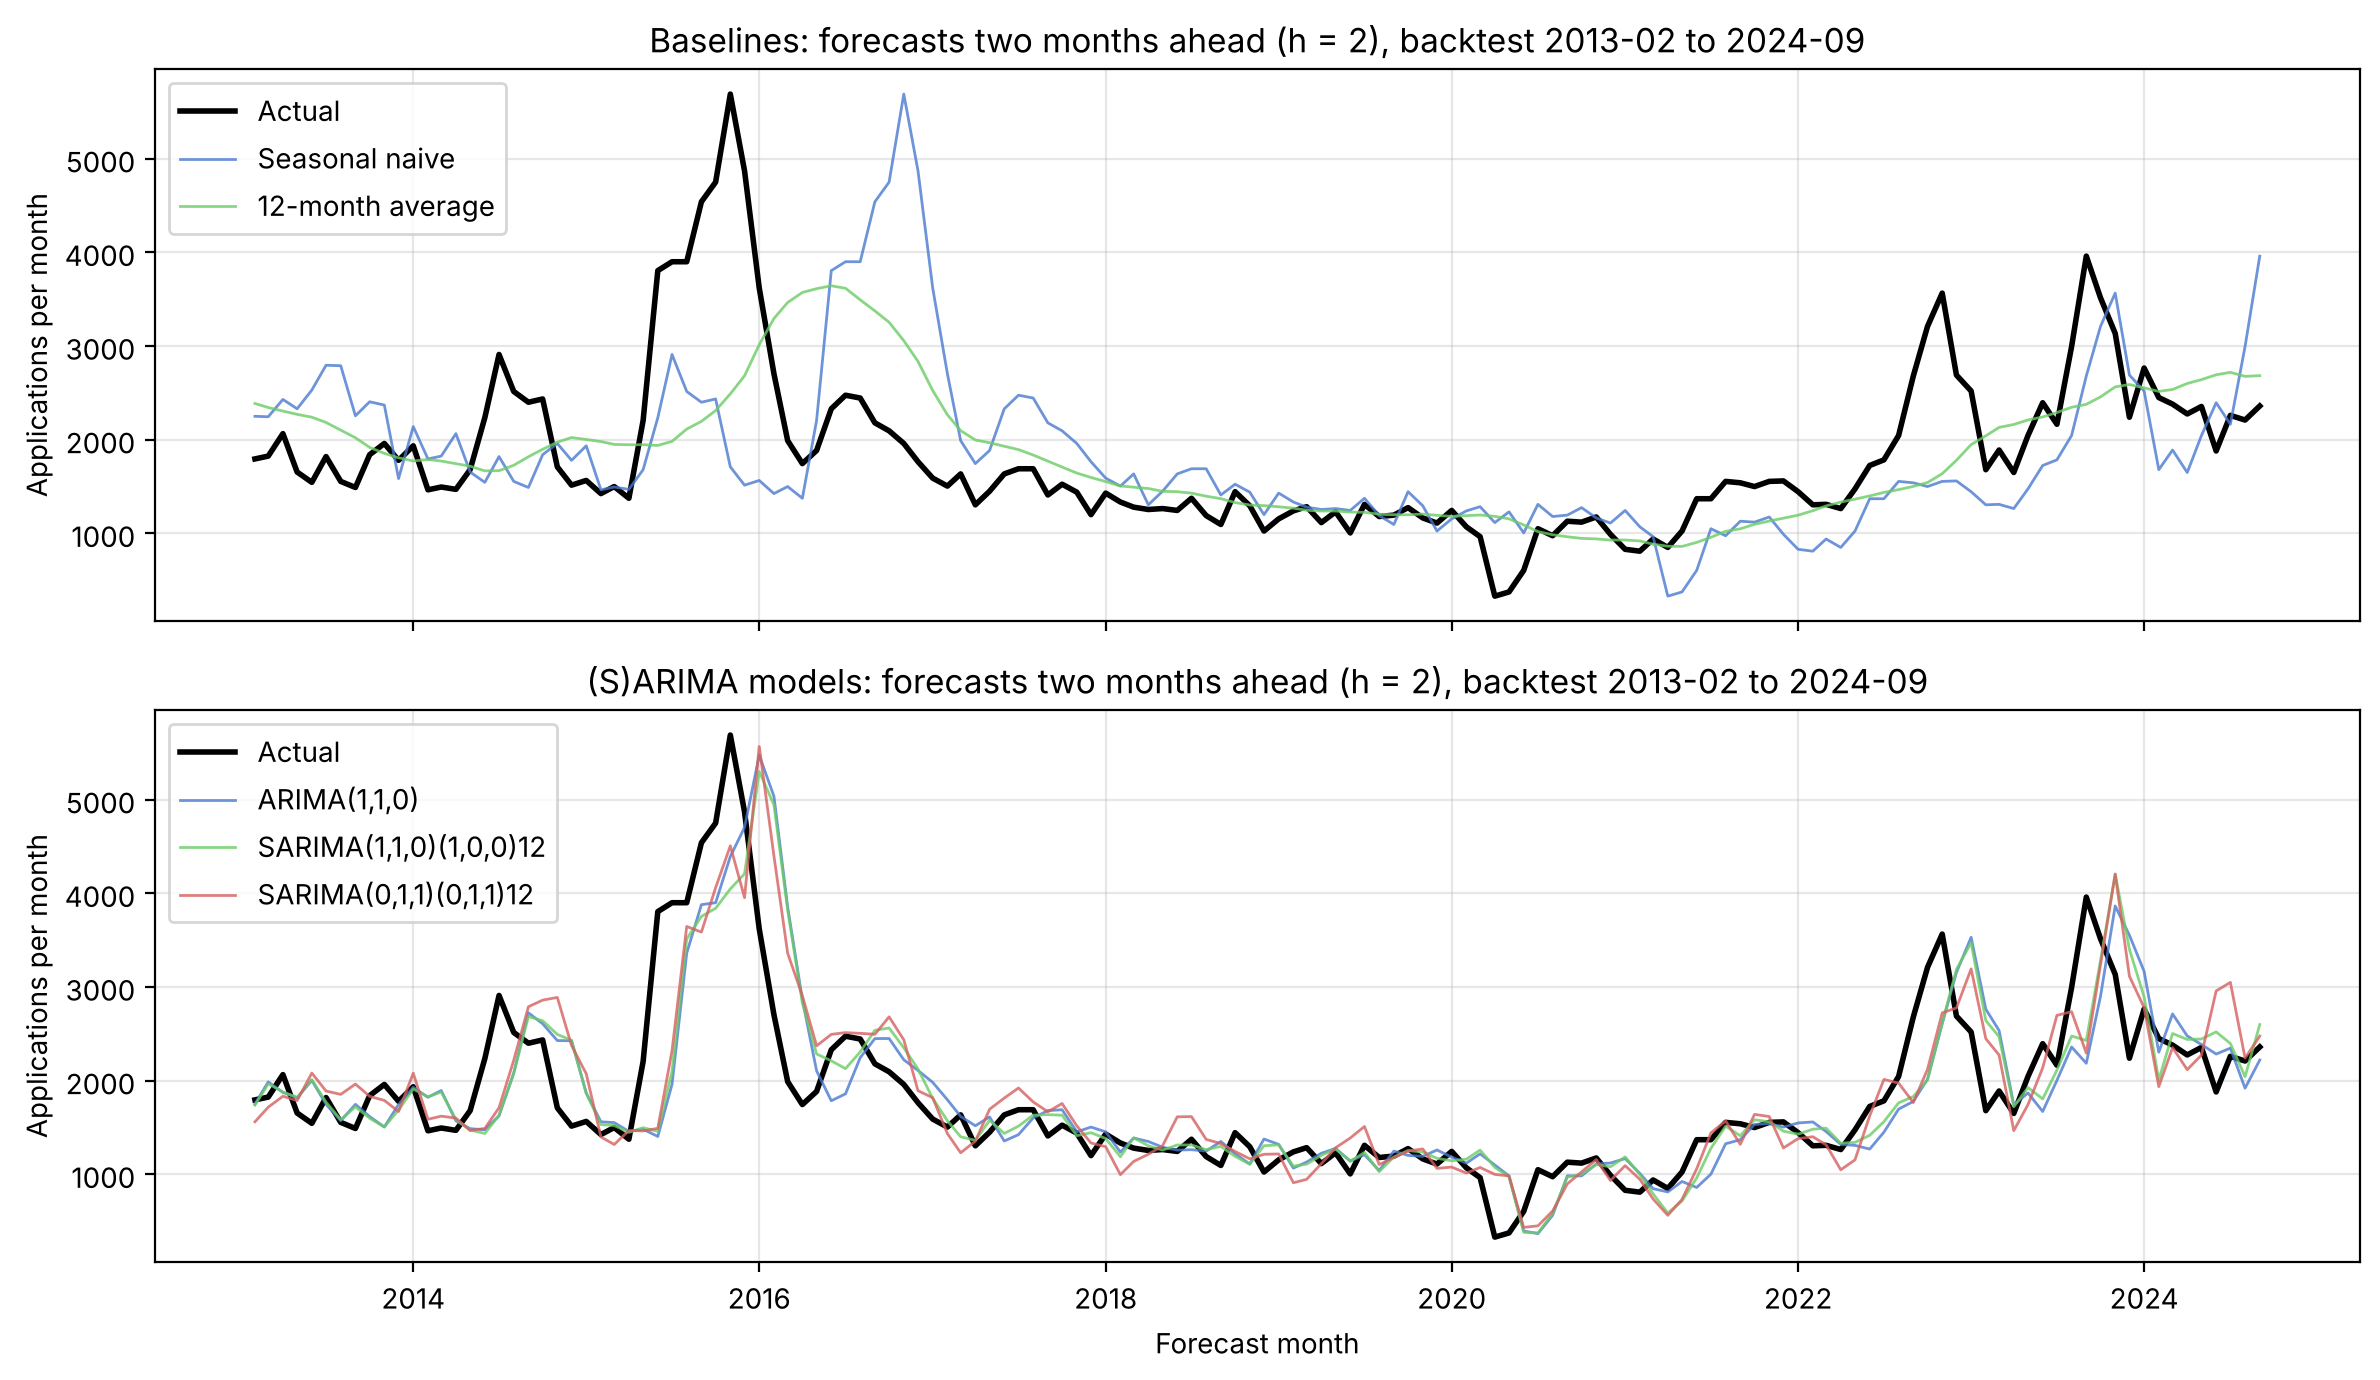

In [9]:
h2 = forecasts[forecasts["h"] == 2]
actual = h2[h2["model"] == "Seasonal naive"].set_index("month")["actual"]

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
groups = [["Seasonal naive", "12-month average"],
          ["ARIMA(1,1,0)", "SARIMA(1,1,0)(1,0,0)12", "SARIMA(0,1,1)(0,1,1)12"]]
titles = ["Baselines", "(S)ARIMA models"]

for ax, names, title in zip(axes, groups, titles):
    ax.plot(actual.index, actual, color="black", linewidth=2, label="Actual")
    for name in names:
        one = h2[h2["model"] == name].set_index("month")["forecast"]
        ax.plot(one.index, one, linewidth=1, alpha=0.8, label=name)
    ax.set_title(f"{title}: forecasts two months ahead (h = 2), backtest 2013-02 to 2024-09")
    ax.set_ylabel("Applications per month")
    ax.legend(loc="upper left")
    ax.grid(alpha=0.3)
axes[1].set_xlabel("Forecast month")
plt.tight_layout()
plt.savefig("../output/figures/02_backtest_forecasts_h2.png")
plt.show()

**What we see.**
- **Seasonal naive** (top, blue) repeats the pattern of the year before: the 2015 peak comes back as a forecast peak of more than 5,000 one year later, at the end of 2016, when the actual numbers were much lower.
- **12-month average** (top, green) is smooth and reacts slowly: its highest point comes in 2016, months after the actual peak of late 2015.
- **The three (S)ARIMA models** (bottom) follow the actual curve much more closely, but with a delay: their peaks come a little after the actual peaks of late 2015, 2022 and 2023. No model foresaw the sudden drop of spring 2020; the forecasts went down only afterwards.

**What this means for us.** From the picture, the (S)ARIMA models follow the level better than the two baselines, but they react late to sudden changes, because they only use the past of the series itself. Whether this gives smaller errors, we measure in `03_evaluate.ipynb`. The delay is also the reason to test indicators later: if arrivals in Italy rise before applications in Switzerland, they could signal a change earlier.

## 7. Save the forecasts

In [10]:
forecasts.to_csv("../data/processed/backtest_forecasts.csv", index=False)
print("Saved", forecasts.shape[0], "forecasts with the columns", list(forecasts.columns))

Saved 2520 forecasts with the columns ['model', 'origin', 'month', 'h', 'forecast_log', 'actual_log', 'forecast', 'actual']


## Summary

- **Setup:** cutoff around the 15th of month $m$, last known month $m-1$ (the origin); forecasts for $h = 1, 2, 3$; main horizon $h = 2$.
- **Backtest:** expanding window, 141 origins from 2012-12 to 2024-08; every model is fitted only on months up to its origin; no forecast falls into the test period.
- **Candidates:** seasonal naive, 12-month average, ARIMA(1,1,0), SARIMA(1,1,0)(1,0,0)12, SARIMA(0,1,1)(0,1,1)12, all forecasting the log of applications; plus the random walk (last known month), added after the test and evaluated in `03_evaluate.ipynb`, Part B.
- **Output:** 2,520 forecasts in `../data/processed/backtest_forecasts.csv`, used by `03_evaluate.ipynb`.